In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

In [2]:
df_dir = Path(r"D:\Gus\geog606\code\data\dataframes")
fig_dir = Path(r"D:\Gus\geog606\code\figures")

In [3]:
df_wide = pd.read_csv(df_dir / "vancouver_gi_wide.csv").dropna() # pivot table
df_long = pd.read_csv(df_dir / "vancouver_gi_long.csv").dropna() 

df_long.head()

,Cell_ID,UTM_X,UTM_Y,Epoch,Norm,Gi_Bin,GiZScore,GiPValue
0,3645,489885.0,5462475.0,lst_06,0.009356,-3,-8.306022,0.0
1,4136,489885.0,5462445.0,lst_06,0.006392,-3,-8.306022,0.0
2,4626,489855.0,5462415.0,lst_06,0.017415,-3,-9.131539,0.0
3,5117,489855.0,5462385.0,lst_06,0.024250,-3,-9.683956,0.0
4,5601,489645.0,5462355.0,lst_06,0.137017,-3,-12.515527,0.0


In [4]:
# get the size of extent
df_high_conf = df_long[df_long["Gi_Bin"] >= 2].groupby('Epoch')
sig_hot_spot_area = df_high_conf.size()
print(sig_hot_spot_area)

area_km = [(item*30*30)*10**-6 for item in sig_hot_spot_area]
area_km 


Epoch
lst_06    60654
lst_17    58784
lst_96    61999
dtype: int64


[54.5886, 52.9056, 55.799099999999996]

In [5]:
colors = {"1996–2005": "#0072B2", "2006–2015": "#E69F00", "2016–2026": "#D55E00"}
epoch_map = {"lst_96": "1996–2005", "lst_06": "2006–2015", "lst_17": "2016–2026"}

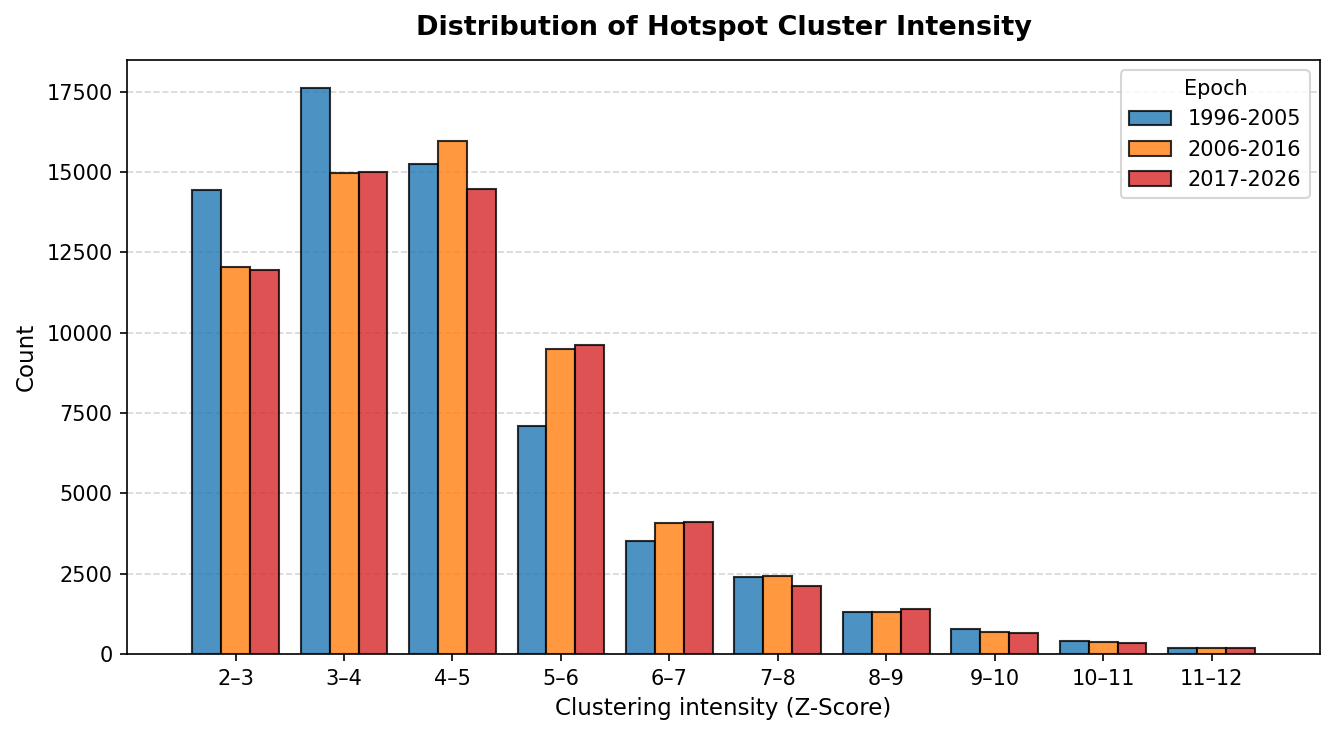

In [8]:
pos_data = df_long[df_long['GiZScore'] >= 1.96]

# Define epochs in chronological order and prepare data list
epochs = ['lst_96', 'lst_06', 'lst_17']
epochs_lables = ['1996-2005', '2006-2016', '2017-2026']
colors = ["#1f77b4", "#ff7f0e", "#d62728"]

grouped_z = [pos_data[pos_data['Epoch'] == ep]['GiZScore'] for ep in epochs]

fig, ax = plt.subplots(figsize=(9, 5), dpi=150)

bins = np.arange(2, 13, 1)

ax.hist(grouped_z, bins=bins, color=colors, edgecolor="black", label=epochs_lables, zorder=3, alpha=0.8)

# ========================================== Generated with gemini
bin_centers = (bins[:-1] + bins[1:]) / 2
bin_ranges = [f"{low}–{high}" for low, high in zip(bins[:-1], bins[1:])]
ax.set_xticks(bin_centers)
ax.set_xticklabels(bin_ranges)
# ==========================================

# Formatting titles, axes, legend, grid, and spines
ax.set_title("Distribution of Hotspot Cluster Intensity", fontsize=13, fontweight="bold", pad=12)
ax.set_xlabel("Clustering intensity (Z-Score)", fontsize=11)
ax.set_ylabel("Count", fontsize=11)
ax.set_xlim(1.5, 12.5)
ax.legend(title="Epoch")

ax.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
fig.savefig(fig_dir / "dist_cluster_intensity.png", dpi=300, bbox_inches="tight")
plt.show()

C:\Users\Gus\AppData\Local\Temp\ipykernel_33712\96392785.py:7: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.sample(n=min(len(g), sample_size), random_state=42))


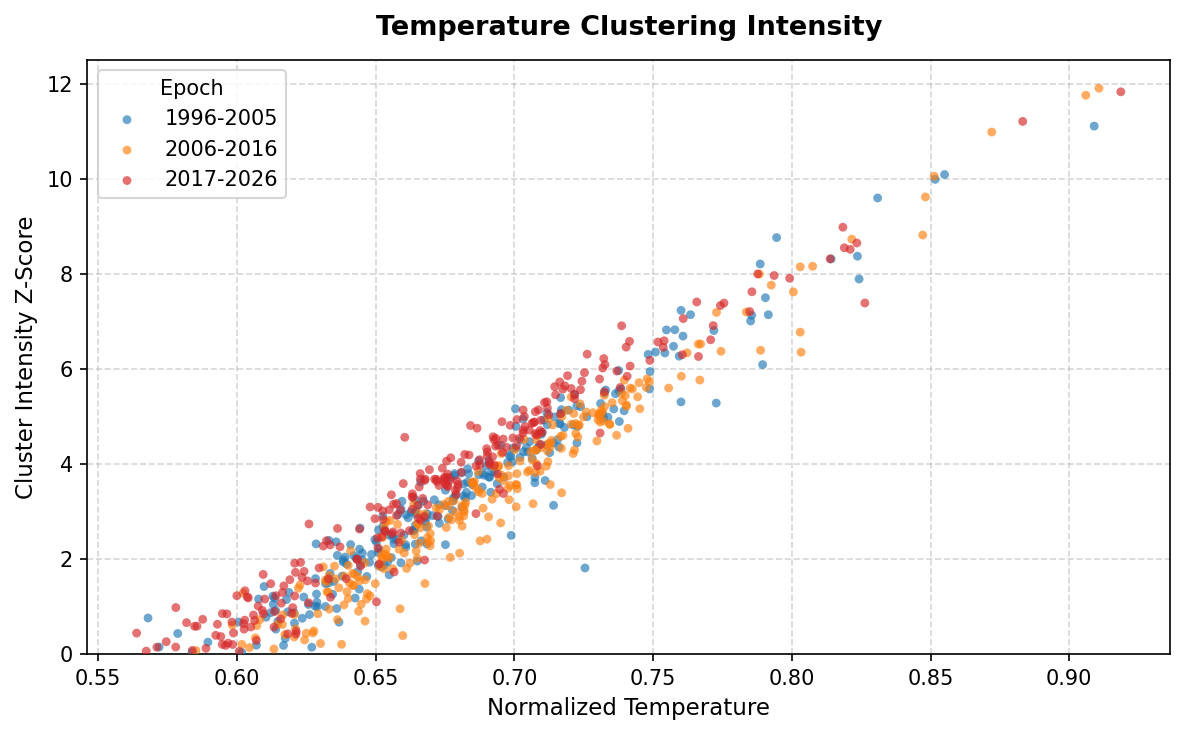

In [9]:

pos_data = df_long[df_long['GiZScore'] >= 0]

# ====================== Code block Generated with gemini (LLM) to create samples.
sample_size = 250
sampled_df = (
    pos_data.groupby('Epoch', group_keys=False)
    .apply(lambda g: g.sample(n=min(len(g), sample_size), random_state=42))
    .sample(frac=1, random_state=42)  # Shuffle drawing order
)
# =======================

# Set up figure and axis
fig, ax = plt.subplots(figsize=(8, 5), dpi=150)

# Map actual column values to display labels
epoch_map = {
    'lst_96': ('1996-2005', '#1f77b4'),
    'lst_06': ('2006-2016', '#ff7f0e'),
    'lst_17': ('2017-2026', '#d62728')
}

for ep_val, (label, color) in epoch_map.items():
    subset = sampled_df[sampled_df['Epoch'] == ep_val]
    ax.scatter(
        subset['Norm'],
        subset['GiZScore'],
        label=label,
        color=color,
        alpha=0.65,
        s=18,
        edgecolors='none',
        zorder=3
    )

# 3. Set X and Y ranges cleanly with 5% padding so edge points aren't clipped
x_min, x_max = sampled_df['Norm'].min(), sampled_df['Norm'].max()
x_pad = (x_max - x_min) * 0.05
ax.set_xlim(x_min - x_pad, x_max + x_pad)  # Or use ax.set_xlim(0, 1) if Norm is strictly 0–1
ax.set_ylim(bottom=0)

# Formatting titles, axes, legend, grid, and spines
ax.set_title("Temperature Clustering Intensity", fontsize=13, fontweight="bold", pad=12)
ax.set_xlabel("Normalized Temperature", fontsize=11)
ax.set_ylabel("Cluster Intensity Z-Score", fontsize=11)
ax.legend(title="Epoch")

ax.grid(True, linestyle="--", alpha=0.5, zorder=0)


plt.tight_layout()
fig.savefig(fig_dir / "nt_vs_cluster_intensity.png", dpi=300, bbox_inches="tight")
plt.show()

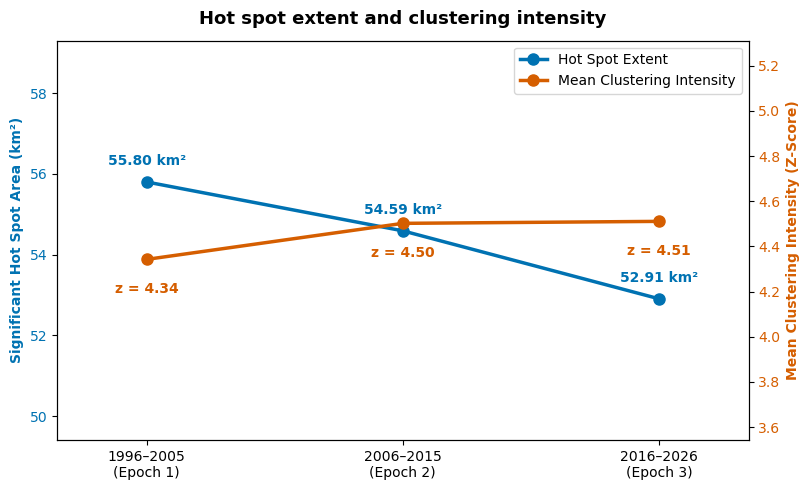

In [28]:
# generated with help from Gemini AI

plt.rcParams["axes.spines.right"] = True

epochs_ordered = ["lst_96", "lst_06", "lst_17"]
epoch_lables = ["1996–2005\n(Epoch 1)", "2006–2015\n(Epoch 2)", "2016–2026\n(Epoch 3)"]
x_pos = np.arange(len(epochs_ordered))

# Series 1 (Left Axis): Total Significant Hot Spot Area (km², Gi_Bin >= 2).... 0.0009  is area per row
hs_areas = np.array([(df_wide[f"Gi_Bin_{ep}"] >= 2).sum() * 0.0009 for ep in epochs_ordered])

# Series 2 (Right Axis): Mean Gi* Z-Score inside Hot Spot Core (clustering intensity)
core_mean_z = np.array([
    df_wide.loc[df_wide[f"Gi_Bin_{ep}"] >= 2, f"GiZScore_{ep}"].mean()
    for ep in epochs_ordered
])

fig, ax1 = plt.subplots(figsize=(8.2, 5.0))

color_area = "#0072B2"
color_z = "#D55E00"

# Plot Series 1 (Left Axis)
line1 = ax1.plot(
    x_pos, hs_areas, color=color_area, marker="o", markersize=8,
    linewidth=2.5, label="Hot Spot Extent"
)
ax1.set_ylabel("Significant Hot Spot Area (km²)", color=color_area, fontweight="bold")
ax1.tick_params(axis="y", labelcolor=color_area)

# Dynamic y-limits for Left Axis with generous top/bottom buffer
area_pad = max((hs_areas.max() - hs_areas.min()) * 0.8, 3.5)
ax1.set_ylim(hs_areas.min() - area_pad, hs_areas.max() + area_pad)

for idx, val in enumerate(hs_areas):
    ax1.annotate(
        f"{val:.2f} km²",
        xy=(x_pos[idx], val),
        xytext=(0, 10), textcoords="offset points",
        ha="center", va="bottom", color=color_area, fontweight="bold"
    )

# Plot Series 2 (Right Axis)
ax2 = ax1.twinx()
line2 = ax2.plot(
    x_pos, core_mean_z, color=color_z, marker="o", markersize=8, linewidth=2.5, label="Mean Clustering Intensity"
)
ax2.set_ylabel("Mean Clustering Intensity (Z-Score)", color=color_z, fontweight="bold")
ax2.tick_params(axis="y", labelcolor=color_z)

# Dynamic y-limits for Right Axis so high z-scores never clip
z_pad = max((core_mean_z.max() - core_mean_z.min()) * 0.8, 0.8)
ax2.set_ylim(core_mean_z.min() - z_pad, core_mean_z.max() + z_pad)

for idx, val in enumerate(core_mean_z):
    ax2.annotate(
        f"z = {val:.2f}",
        xy=(x_pos[idx], val),
        xytext=(0, -16), textcoords="offset points",
        ha="center", va="top", color=color_z, fontweight="bold"
    )

# Add horizontal padding so labels at x=0 and x=2 never touch the y-axis spines
ax1.set_xlim(-0.35, len(epochs_ordered) - 0.65)
ax1.set_xticks(x_pos)
ax1.set_xticklabels(epoch_lables)

# Place legend cleanly above the axes frame and adjust title spacing
lines = line1 + line2
labels = [l.get_label() for l in lines]
ax1.legend(
    lines, labels,
)
ax1.set_title("Hot spot extent and clustering intensity", fontsize=13, fontweight="bold", pad=12)

fig.tight_layout()
fig.savefig(fig_dir / "fig3_dual_axis_timeseries.png", dpi=300, bbox_inches="tight")
plt.show()